# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [1]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [2]:
final_aviation_df = pd.read_csv('aviationData/FinalAviationData.csv', low_memory=False)

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [3]:
#New derived column: Plane.Type -> Uses Estimated.Occupants column to set passenger threshold
#Assumption: These groups are based on recorded occupants and don't verify the actual plane capacity
final_aviation_df['Plane.Type'] = np.select(
    [
        final_aviation_df['Estimated.Occupants'] <= 20,
        final_aviation_df['Estimated.Occupants'] > 20
    ],
    ['Small', 'Large'],
    default='Unknown'
)

In [4]:
final_aviation_df['Plane.Type'].value_counts(dropna=False)

Plane.Type
Small      54371
Unknown    11100
Large       1851
Name: count, dtype: int64

#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

Assumption: The mean of different Makes is highly influenced by the number of fully recorded accidents

In [5]:
#Subset the dataset for records where none of the columns:
#Plane.Type, Make, Fatal.Serious.Injury.Rate have null values
analysis_df = final_aviation_df[
    final_aviation_df['Plane.Type'].isin([
        'Small',
        'Large'
    ])
    & final_aviation_df['Make'].notna()
    & final_aviation_df['Fatal.Serious.Injury.Rate'].notna()
].copy()

In [6]:
# Calculate mean injury fraction and number of usable records per make
make_summary = (
    analysis_df
    .groupby(['Plane.Type', 'Make'])
    .agg(
        #Find the injury rate mean of each make and type based on the no of accident records
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean'),
        #Counts the number of records for each make and plane type
        Accident_Count=('Fatal.Serious.Injury.Rate', 'count')
    )
    .reset_index()
)

In [7]:
make_summary.head()

,Plane.Type,Make,Mean_Injury_Fraction,Accident_Count
0,Large,AERO COMMANDER,0.000000,1
1,Large,AEROSPATIALE,0.039126,29
2,Large,AIRBUS,0.063233,203
3,Large,BEECH,0.192446,13
4,Large,BELL,1.000000,1


In [8]:
# Select the 15 makes with the lowest mean fraction in each group
top15_makes = (
    make_summary
    .sort_values('Mean_Injury_Fraction')
    .groupby('Plane.Type')
    .head(15)
)

In [9]:
display(
    top15_makes.sort_values(
        ['Plane.Type', 'Mean_Injury_Fraction']
    )
)

,Plane.Type,Make,Mean_Injury_Fraction,Accident_Count
0,Large,AERO COMMANDER,0.000000,1
11,Large,HUGHES,0.000000,1
14,Large,MOONEY,0.000000,1
16,Large,SIKORSKY,0.000000,1
17,Large,SWEARINGEN,0.000000,1
6,Large,CESSNA,0.002051,13
13,Large,MCDONNELL DOUGLAS,0.036446,254
1,Large,AEROSPATIALE,0.039126,29
5,Large,BOEING,0.045104,1134
2,Large,AIRBUS,0.063233,203


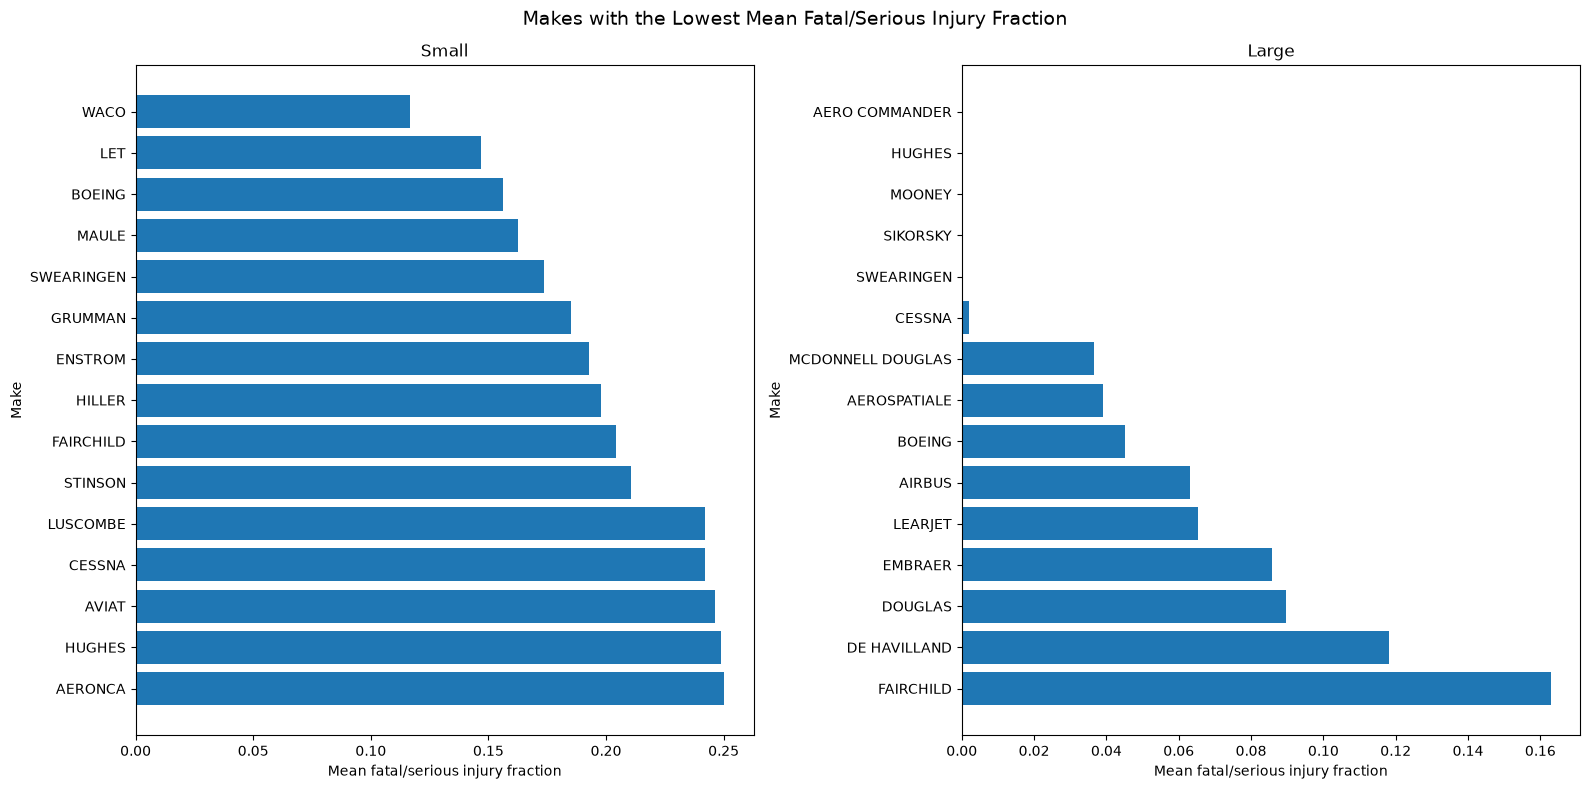

In [10]:
groups = [
    'Small',
    'Large'
]
#plt.subplots() creates a figure and one or more plotting areas.
#1, 2 means 1 row and 2 columns of plots.
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
#zip(axes, groups) function pairs each plotting area with its group
for ax, group in zip(axes, groups):
    plot_data = (
        top15_makes[top15_makes['Plane.Type'] == group]
        .sort_values('Mean_Injury_Fraction', ascending=True)
    )
    #ax.barh() creates a horizontal bar chart.
    ax.barh(
        plot_data['Make'],
        plot_data['Mean_Injury_Fraction']
    )
    
    ax.set_title(group)
    ax.set_xlabel('Mean fatal/serious injury fraction')
    ax.set_ylabel('Make')
    #Puts lowest value on top
    ax.invert_yaxis()

fig.suptitle(
    'Makes with the Lowest Mean Fatal/Serious Injury Fraction',
    fontsize=14
)
plt.tight_layout()
plt.show()

**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [11]:
# Filter for small aircraft and usable injury rates
small_df = final_aviation_df[
    (final_aviation_df['Plane.Type'] == 'Small')
    & final_aviation_df['Make'].notna()
    & final_aviation_df['Fatal.Serious.Injury.Rate'].notna()
].copy()

# Calculate the mean injury rate and accident count for each make
small_make_summary = (
    small_df
    .groupby('Make')
    .agg(
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean'),
        Accident_Count=('Fatal.Serious.Injury.Rate', 'count')
    )
    .reset_index()
)

# Select the 10 makes with the lowest mean injury rates
top10_small_makes = (
    small_make_summary
    .sort_values('Mean_Injury_Fraction')
    .head(10)
)

In [12]:
# Display the summary table 
display(
    top10_small_makes[
        ['Make', 'Mean_Injury_Fraction', 'Accident_Count']
    ]
)

,Make,Mean_Injury_Fraction,Accident_Count
45,WACO,0.116519,113
29,LET,0.146789,109
11,BOEING,0.156084,551
31,MAULE,0.162527,459
43,SWEARINGEN,0.173605,126
23,GRUMMAN,0.185029,952
19,ENSTROM,0.192797,236
25,HILLER,0.197814,305
22,FAIRCHILD,0.204371,123
42,STINSON,0.210539,359


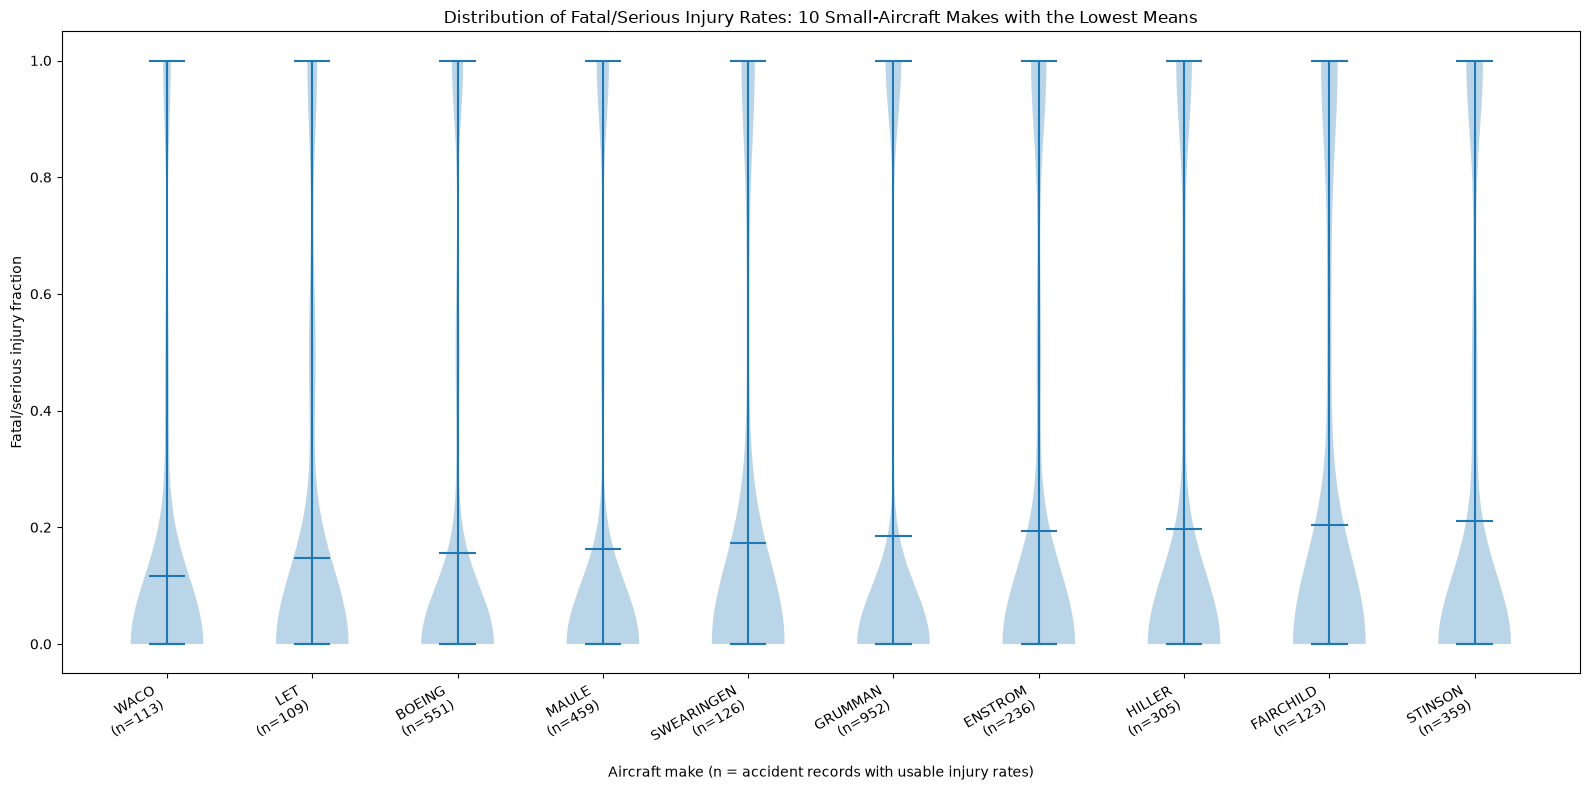

In [13]:
# Arrange the individual accident rates in the same order
make_order = top10_small_makes['Make'].tolist()

violin_data = [
    small_df.loc[
        small_df['Make'] == make,
        'Fatal.Serious.Injury.Rate'
    ].to_numpy()
    for make in make_order
]

# Create labels that include the accident count
accident_counts = top10_small_makes.set_index('Make')['Accident_Count']

make_labels = [
    f"{make}\n(n={accident_counts[make]})"
    for make in make_order
]

# Draw the violin plot
fig, ax = plt.subplots(figsize=(16, 8))

ax.violinplot(
    violin_data,
    showmeans=True,
    showmedians=True,
    showextrema=True
)

ax.set_xticks(range(1, len(make_order) + 1))
ax.set_xticklabels(make_labels, rotation=30, ha='right')

ax.set_title(
    'Distribution of Fatal/Serious Injury Rates: '
    '10 Small-Aircraft Makes with the Lowest Means'
)
ax.set_xlabel('Aircraft make (n = accident records with usable injury rates)')
ax.set_ylabel('Fatal/serious injury fraction')

#ax.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

In [14]:
# Filter for large aircraft with usable injury rates
large_df = final_aviation_df[
    (final_aviation_df['Plane.Type'] == 'Large')
    & final_aviation_df['Make'].notna()
    & final_aviation_df['Fatal.Serious.Injury.Rate'].notna()
].copy()

# Calculate the mean injury rate and accident count for each make
large_make_summary = (
    large_df
    .groupby('Make')
    .agg(
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean'),
        Accident_Count=('Fatal.Serious.Injury.Rate', 'count')
    )
    .reset_index()
)

# Select the 10 makes with the lowest mean injury rates
top10_large_makes = (
    large_make_summary
    .sort_values('Mean_Injury_Fraction')
    .head(10)
)

In [15]:
display(
    top10_large_makes[
        ['Make', 'Mean_Injury_Fraction', 'Accident_Count']
    ]
)

,Make,Mean_Injury_Fraction,Accident_Count
0,AERO COMMANDER,0.000000,1
11,HUGHES,0.000000,1
14,MOONEY,0.000000,1
16,SIKORSKY,0.000000,1
17,SWEARINGEN,0.000000,1
6,CESSNA,0.002051,13
13,MCDONNELL DOUGLAS,0.036446,254
1,AEROSPATIALE,0.039126,29
5,BOEING,0.045104,1134
2,AIRBUS,0.063233,203


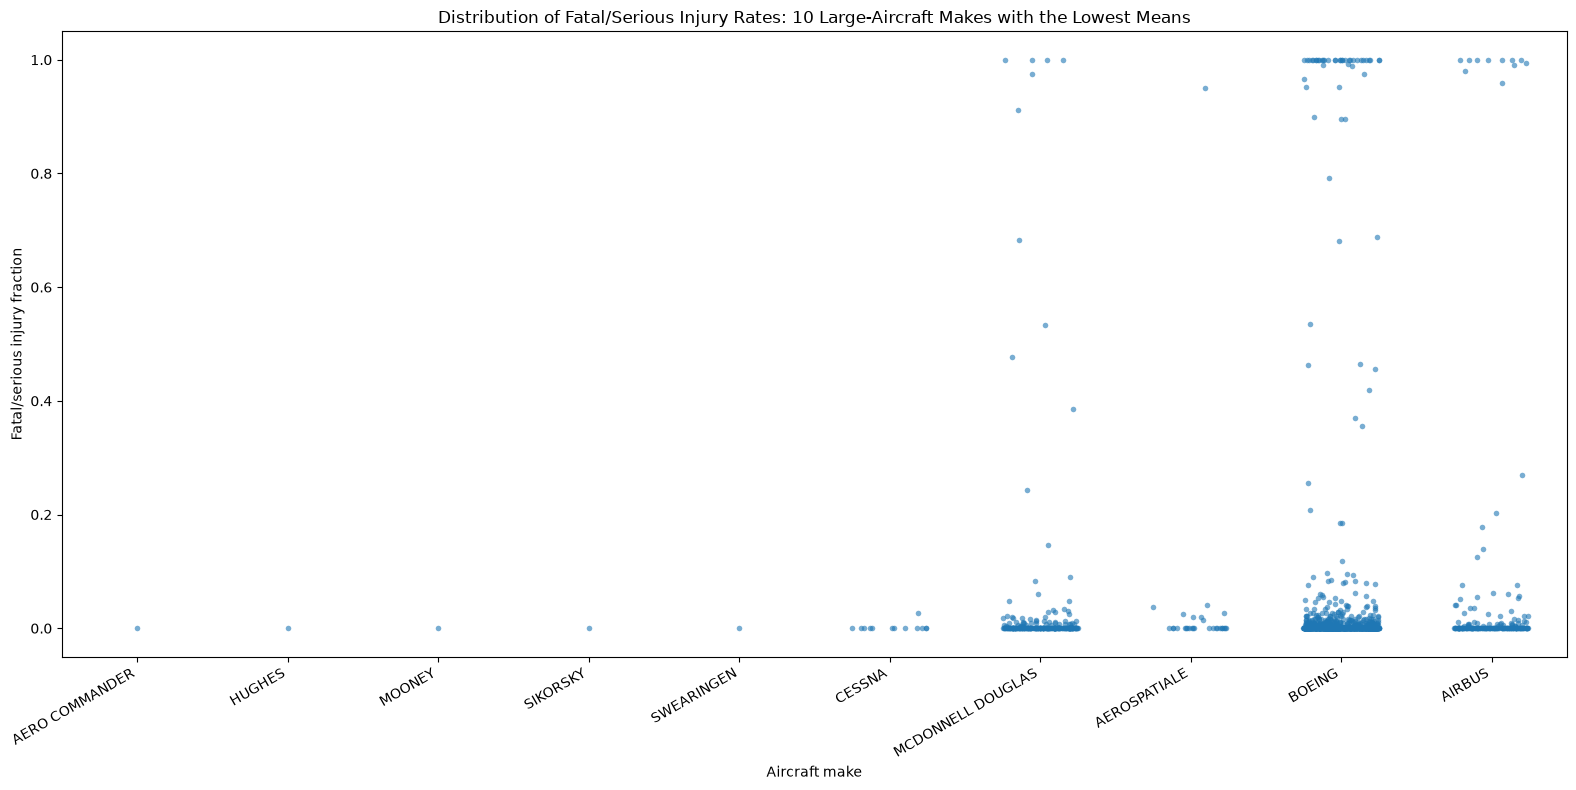

In [16]:
selected_makes = top10_large_makes['Make'].tolist()

plot_df = large_df[
    large_df['Make'].isin(selected_makes)
].copy()

# Create the strip plot
fig, ax = plt.subplots(figsize=(16, 8))

sns.stripplot(
    data=plot_df,
    x='Make',
    y='Fatal.Serious.Injury.Rate',
    order=selected_makes,
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax
)

# Format the plot
ax.set_title(
    'Distribution of Fatal/Serious Injury Rates: '
    '10 Large-Aircraft Makes with the Lowest Means'
)
ax.set_xlabel('Aircraft make')
ax.set_ylabel('Fatal/serious injury fraction')
#ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [17]:
#Subset the df for records where the columns: 
# Plane.Type, Make, Aircraft.Destroyed all have valid values
destruction_df = final_aviation_df[
    final_aviation_df['Plane.Type'].isin([
        'Small',
        'Large'
    ])
    & final_aviation_df['Make'].notna()
    & final_aviation_df['Aircraft.Destroyed'].notna()
].copy()

In [18]:
destruction_summary = (
    destruction_df
    .groupby(['Plane.Type', 'Make'])
    .agg(
        Destruction_Rate=('Aircraft.Destroyed', 'mean'),
        Accident_Count=('Aircraft.Destroyed', 'count')
    )
    .reset_index()
)

In [19]:
lowest15_destruction = (
    destruction_summary
    .sort_values('Destruction_Rate')
    .groupby('Plane.Type')
    .head(15)
)

In [20]:
display(
    lowest15_destruction.sort_values(
        ['Plane.Type', 'Destruction_Rate']
    )
)

,Plane.Type,Make,Destruction_Rate,Accident_Count
0,Large,AERO COMMANDER,0.000000,1
6,Large,CESSNA,0.000000,6
14,Large,SWEARINGEN,0.000000,1
1,Large,AEROSPATIALE,0.071429,14
5,Large,BOEING,0.084629,579
12,Large,MCDONNELL DOUGLAS,0.098039,153
2,Large,AIRBUS,0.136364,88
9,Large,EMBRAER,0.155556,45
8,Large,DOUGLAS,0.170213,47
7,Large,DE HAVILLAND,0.222222,18


#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

Comments based on rate of destruction and fatally injured mean.

LARGE AIRCRAFTS:
    Boeing, McDonell Doughlas and Airbus are makes that display a low destruction rate despite having more
    recorded accident counts.
    Boeing is the make with low fatality rate despite having the highest no of recorded accidents with 
    McDonell Doughlas coming second and Airbus third
    Findings for large aircrafts are heavily influenced by lack of sufficient accident records for many makes

SMALL AIRCRAFTS:
    Boeing and Maule stand out as having the lowest destruction fraction despite having more recorded accidents
    Gruman exhibits a low fataly injured mean despite having a high number of recorded accidents followed by 
    Boeing suggesting more accidents happen but have a low destruction and fatality rate
    

    

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

Both types

In [21]:
#Subset the df based on: Plane.Type, Make_model, Fatal.Serious.Injury.Rate
analysis_df = final_aviation_df[
    final_aviation_df['Plane.Type'].isin([
        'Small',
        'Large'
    ])
    & final_aviation_df['Make_Model'].notna()
    & final_aviation_df['Fatal.Serious.Injury.Rate'].notna()
].copy()

In [22]:
# Count usable accident records for each aircraft type and make/model
model_counts = (
    analysis_df
    .groupby(['Plane.Type', 'Make_Model'])
    #Counts the rows in each group
    .size()
    .reset_index(name='Accident_Count')
)

In [23]:
# Keep make/model combinations with at least 10 records
eligible_models = model_counts[
    model_counts['Accident_Count'] >= 10
]

# Keep individual records belonging to eligible combinations
analysis_df = analysis_df.merge(
    eligible_models[['Plane.Type', 'Make_Model']],
    on=['Plane.Type', 'Make_Model'],
    how='inner'
)

In [24]:
# Check the number of eligible combinations per aircraft type
display(
    eligible_models.groupby('Plane.Type')
    .size()
    .reset_index(name='Eligible_Make_Model_Combinations')
)

,Plane.Type,Eligible_Make_Model_Combinations
0,Large,41
1,Small,727


In [25]:
# Check the remaining accident records and mean injury rates
display(
    analysis_df.groupby('Plane.Type').agg(
        Accident_Records=('Fatal.Serious.Injury.Rate', 'count'),
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean')
    ).reset_index()
)

,Plane.Type,Accident_Records,Mean_Injury_Fraction
0,Large,863,0.050954
1,Small,46006,0.274398


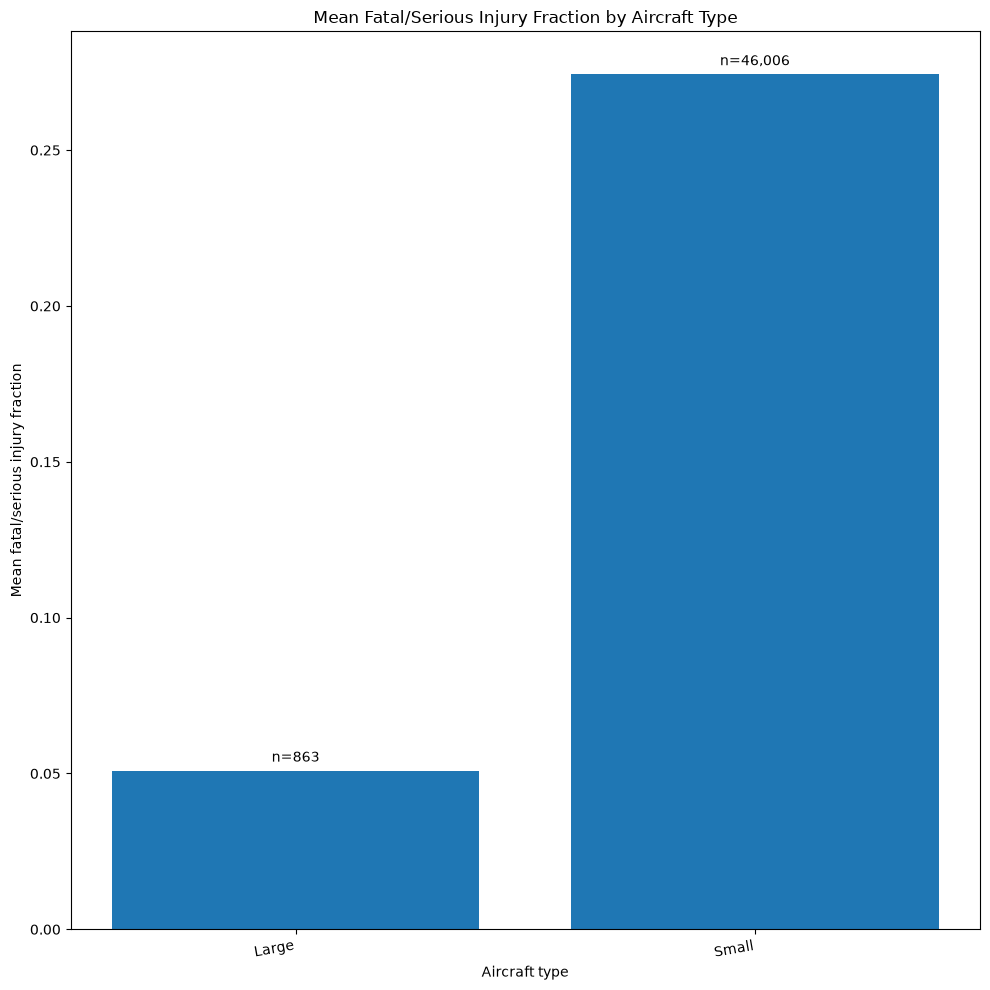

In [26]:

# Calculate the mean injury fraction for each aircraft type
plane_type_summary = (
    analysis_df
    .groupby('Plane.Type')
    .agg(
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean'),
        Accident_Count=('Fatal.Serious.Injury.Rate', 'count')
    )
    .reset_index()
)

# Plot the mean injury fractions
fig, ax = plt.subplots(figsize=(10, 10))

bars = ax.bar(
    plane_type_summary['Plane.Type'],
    plane_type_summary['Mean_Injury_Fraction']
)

ax.bar_label(
    bars,
    labels=[
        f"n={count:,}"
        for rate, count in zip(
            plane_type_summary['Mean_Injury_Fraction'],
            plane_type_summary['Accident_Count']
        )
    ],
    padding=4
)

ax.set_title(
    'Mean Fatal/Serious Injury Fraction by Aircraft Type'
)
ax.set_xlabel('Aircraft type')
ax.set_ylabel('Mean fatal/serious injury fraction')

plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()


**Larger planes**

In [27]:
# Filter for large aircraft with usable injury rates
large_make_model_df = final_aviation_df[
    (final_aviation_df['Plane.Type'] == 'Large')
    & final_aviation_df['Make_Model'].notna()
    & final_aviation_df['Fatal.Serious.Injury.Rate'].notna()
].copy()

# Calculate the mean injury rate and accident count for each make_model
large_make_model_summary = (
    large_make_model_df
    .groupby('Make_Model')
    .agg(
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean'),
        Accident_Count=('Fatal.Serious.Injury.Rate', 'count')
    )
    .reset_index()
)

large_eligible_make_models = large_make_model_summary[large_make_model_summary['Accident_Count'] > 5]


In [28]:
large_eligible_make_models.head()

,Make_Model,Mean_Injury_Fraction,Accident_Count
5,AEROSPATIALE_ATR-42-300,0.005173,12
10,AEROSPATIALE_ATR-72-212,0.013711,7
48,AIRBUS_A319,0.012470,8
60,AIRBUS_A320,0.133566,30
70,AIRBUS_A320-211,0.142857,7


In [29]:
# Select the 10 makes with the lowest mean injury rates
top10_large_make_models = (
    large_eligible_make_models
    .sort_values('Mean_Injury_Fraction')
    .head(10)
)

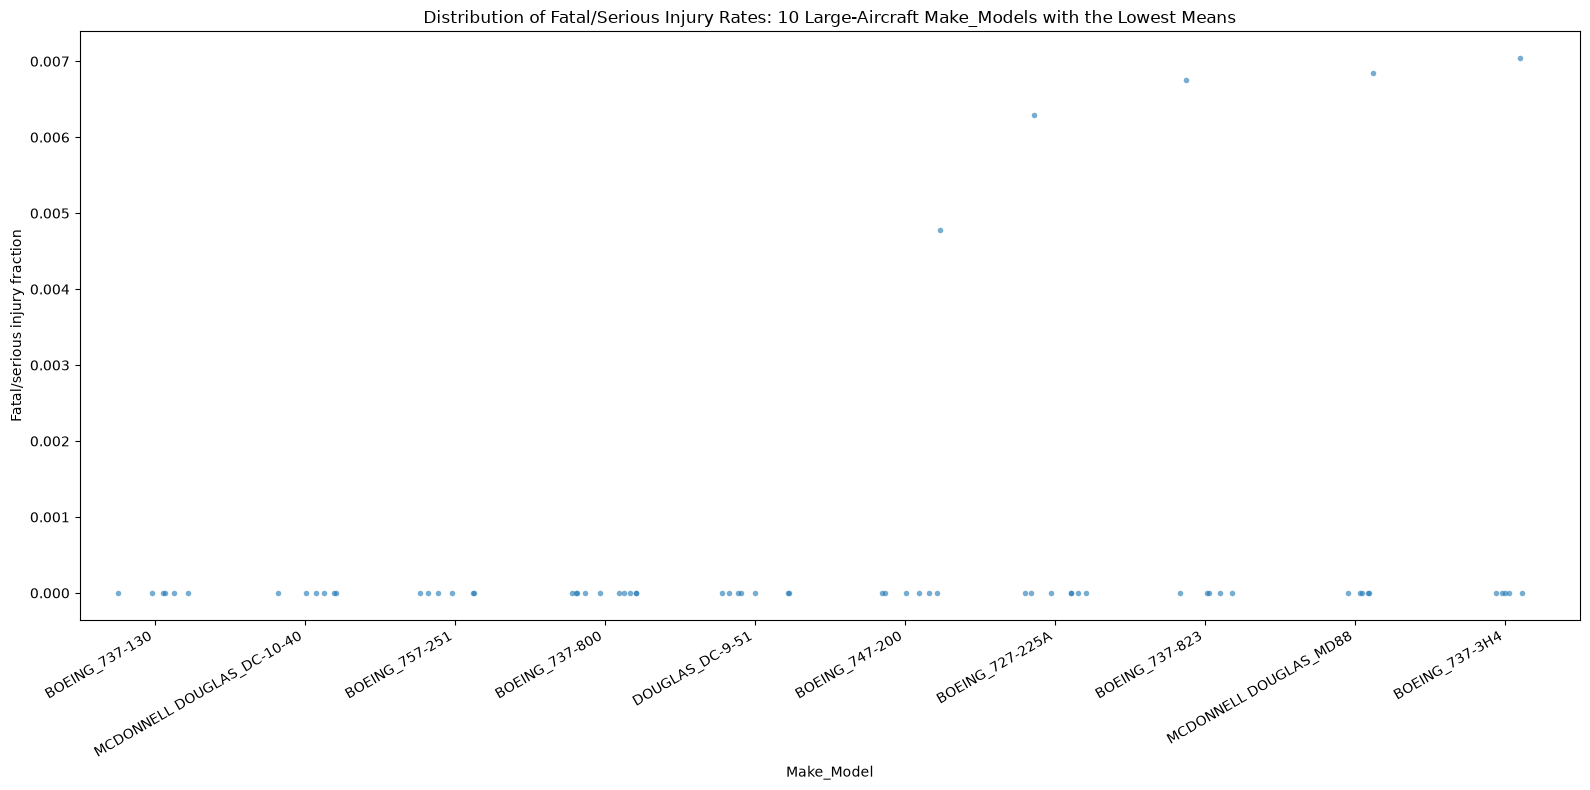

In [30]:
selected_makes = top10_large_make_models['Make_Model'].tolist()

plot_df = large_make_model_df[
    large_make_model_df['Make_Model'].isin(selected_makes)
].copy()

# Create the strip plot
fig, ax = plt.subplots(figsize=(16, 8))

sns.stripplot(
    data=plot_df,
    x='Make_Model',
    y='Fatal.Serious.Injury.Rate',
    order=selected_makes,
    jitter=0.25,
    alpha=0.6,
    size=4,
    ax=ax
)

# Format the plot
ax.set_title(
    'Distribution of Fatal/Serious Injury Rates: '
    '10 Large-Aircraft Make_Models with the Lowest Means'
)
ax.set_xlabel('Make_Model')
ax.set_ylabel('Fatal/serious injury fraction')
#ax.yaxis.set_major_formatter(PercentFormatter(1.0))
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.show()

**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

In [31]:
# Filter for small aircraft and usable injury rates
small_make_model_df = final_aviation_df[
    (final_aviation_df['Plane.Type'] == 'Small')
    & final_aviation_df['Make_Model'].notna()
    & final_aviation_df['Fatal.Serious.Injury.Rate'].notna()
].copy()

# Calculate the mean injury rate and accident count for each make
small_make_model_summary = (
    small_make_model_df
    .groupby('Make_Model')
    .agg(
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean'),
        Accident_Count=('Fatal.Serious.Injury.Rate', 'count')
    )
    .reset_index()
)
#Filter for make_models with more than 20 recorded accidents
eligible_small_model_makes = small_make_model_summary[small_make_model_summary['Accident_Count'] > 20]

# Select the 10 makes with the lowest mean injury rates
top10_small_make_models = (
    eligible_small_model_makes
    .sort_values('Mean_Injury_Fraction')
    .head(10)
)

In [32]:
top10_small_make_models.head()

,Make_Model,Mean_Injury_Fraction,Accident_Count
2411,ENSTROM_F-28A,0.041667,36
1796,CESSNA_560XL,0.047619,21
751,BEECH_C-23,0.066667,30
460,BEECH_1900D,0.066667,30
1299,BOEING_747,0.071429,28


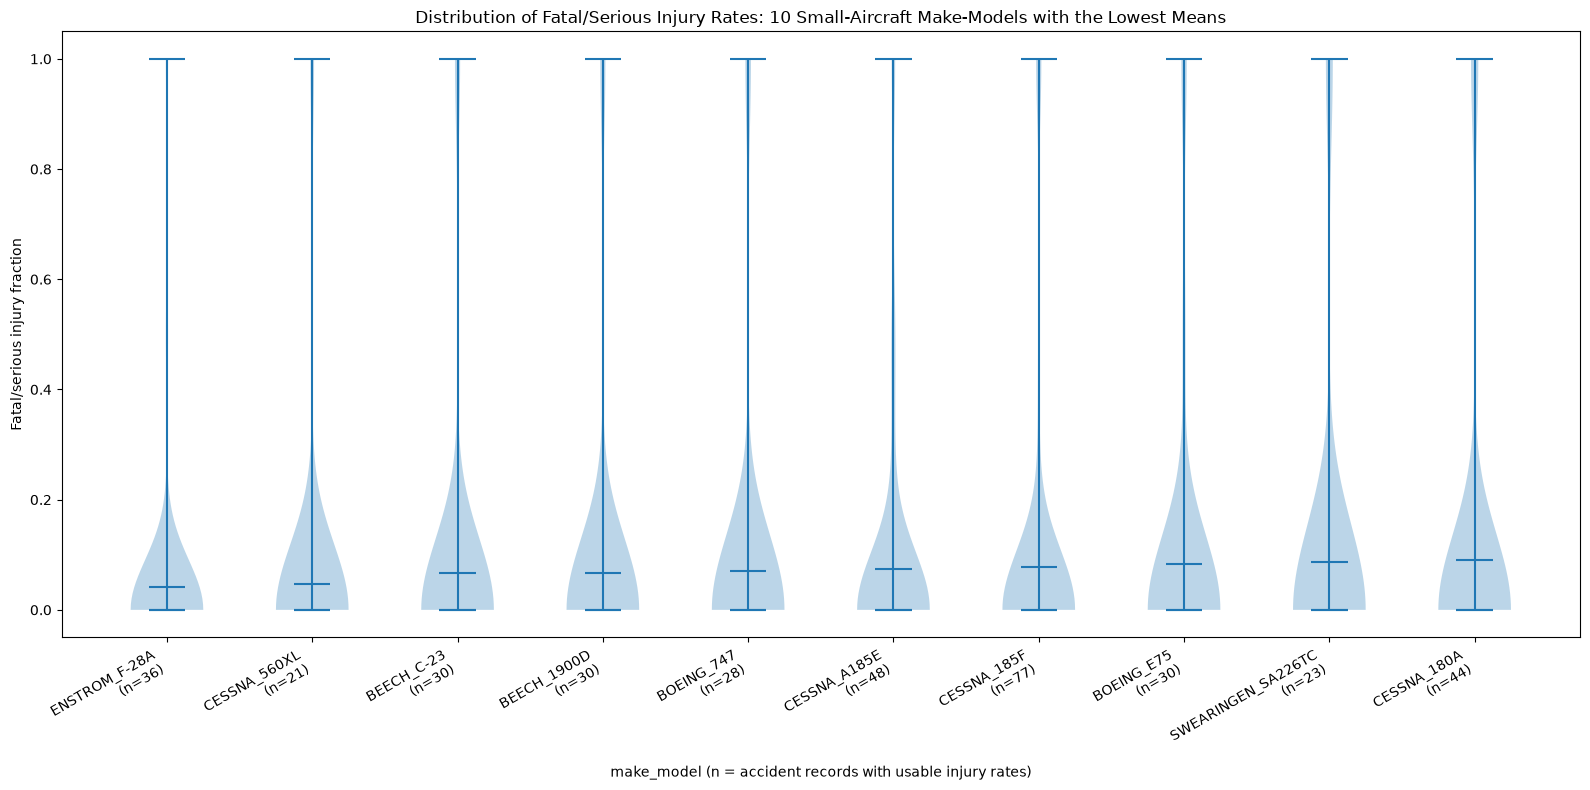

In [33]:
# Arrange the individual accident rates in the same order
make_model_order = top10_small_make_models['Make_Model'].tolist()

violin_data = [
    small_make_model_df.loc[
        small_make_model_df['Make_Model'] == make_model,
        'Fatal.Serious.Injury.Rate'
    ].to_numpy()
    for make_model in make_model_order
]

# Create labels that include the accident count
accident_counts = top10_small_make_models.set_index('Make_Model')['Accident_Count']

make_model_labels = [
    f"{make_model}\n(n={accident_counts[make_model]})"
    for make_model in make_model_order
]

# Draw the violin plot
fig, ax = plt.subplots(figsize=(16, 8))

ax.violinplot(
    violin_data,
    showmeans=True,
    showmedians=True,
    showextrema=True
)

ax.set_xticks(range(1, len(make_model_order) + 1))
ax.set_xticklabels(make_model_labels, rotation=30, ha='right')

ax.set_title(
    'Distribution of Fatal/Serious Injury Rates: '
    '10 Small-Aircraft Make-Models with the Lowest Means'
)
ax.set_xlabel('make_model (n = accident records with usable injury rates)')
ax.set_ylabel('Fatal/serious injury fraction')

#ax.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()

### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

In [ ]:
"""
Findings and Summaries
Note: Findings are highly affected by low recorded accidents across different models
      in the large plane type category
LARGE MODELS:
    Boeing makes models  with the highest survivability rate in this category.
SMALL MODELS:
    Cessna makes models with the highest survivability rate in this category
"""

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

In [51]:
factor_df = final_aviation_df.copy()

# Keep known weather conditions and known flight phases
weather_df = factor_df[
    factor_df['Weather.Condition'].notna()
    & (factor_df['Weather.Condition'] != 'Unknown')
].copy()

phase_df = factor_df[
    factor_df['Broad.phase.of.flight'].notna()
    & (factor_df['Broad.phase.of.flight'] != 'Unknown')
].copy()


In [52]:
weather_summary = (
    weather_df
    .groupby('Weather.Condition')
    .agg(
        Destroyed_Fraction=('Aircraft.Destroyed', 'mean'),
        Destruction_Count=('Aircraft.Destroyed', 'count'),
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean'),
        Injury_Record_Count=('Fatal.Serious.Injury.Rate', 'count')
    )
    .reset_index()
    .sort_values('Weather.Condition')
)

display(weather_summary)

,Weather.Condition,Destroyed_Fraction,Destruction_Count,Mean_Injury_Fraction,Injury_Record_Count
0,IMC,0.587850,4889,0.644427,4196
1,VMC,0.170664,56626,0.222964,48018


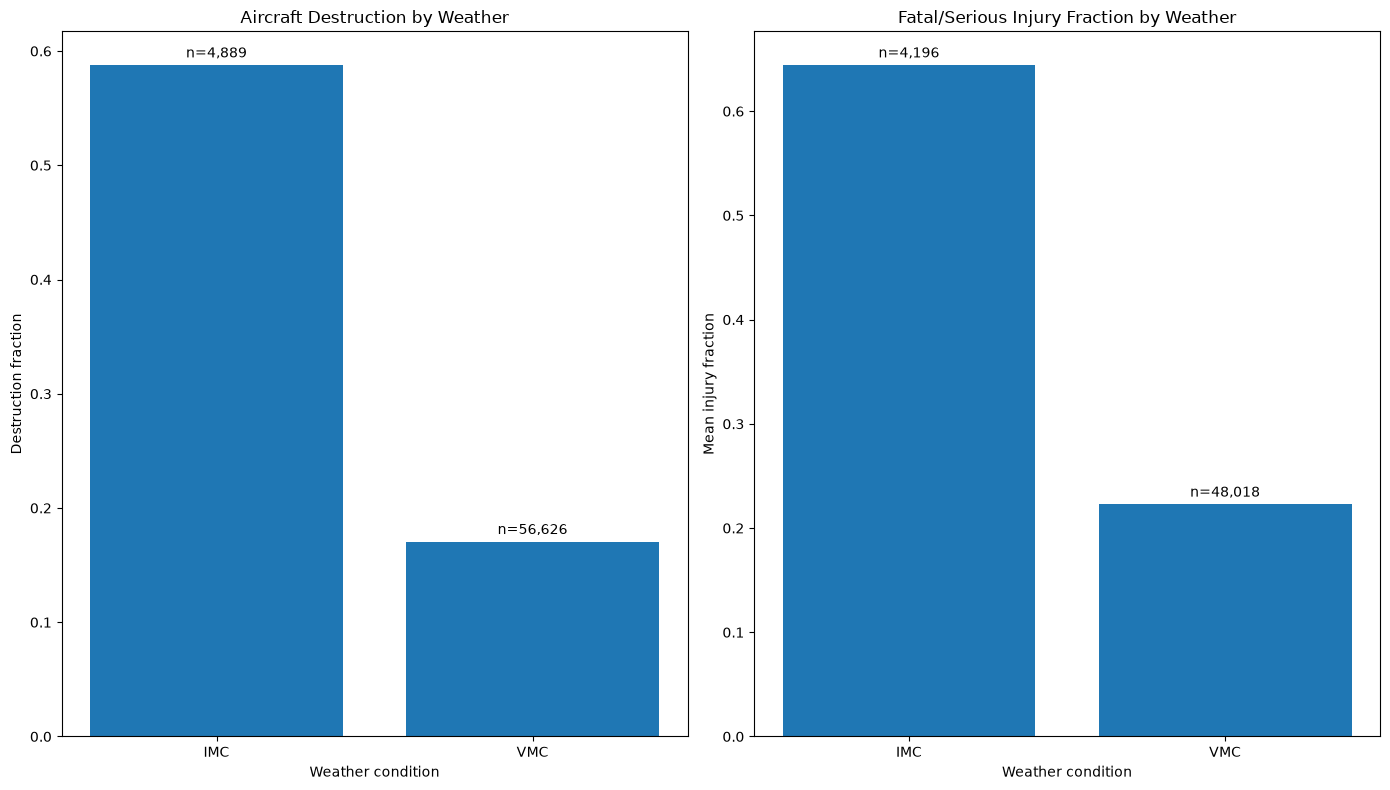

In [53]:

fig, axes = plt.subplots(1, 2, figsize=(14, 8))

# Aircraft destruction fraction
bars = axes[0].bar(
    weather_summary['Weather.Condition'],
    weather_summary['Destroyed_Fraction']
)
axes[0].bar_label(
    bars,
    labels=[
        f'n={int(n):,}'
        for v, n in zip(
            weather_summary['Destroyed_Fraction'],
            weather_summary['Destruction_Count']
        )
    ],
    padding=3
)
axes[0].set_title('Aircraft Destruction by Weather')
axes[0].set_xlabel('Weather condition')
axes[0].set_ylabel('Destruction fraction')


# Fatal/serious injury fraction
bars = axes[1].bar(
    weather_summary['Weather.Condition'],
    weather_summary['Mean_Injury_Fraction']
)
axes[1].bar_label(
    bars,
    labels=[
        f'n={int(n):,}'
        for v, n in zip(
            weather_summary['Mean_Injury_Fraction'],
            weather_summary['Injury_Record_Count']
        )
    ],
    padding=3
)
axes[1].set_title('Fatal/Serious Injury Fraction by Weather')
axes[1].set_xlabel('Weather condition')
axes[1].set_ylabel('Mean injury fraction')

plt.tight_layout()
plt.show()


FINDINGS BASED ON WEATHER CONDITIONS:
    The analysis compared aircraft destruction fractions and mean fatal/serious injury fractions across recorded weather conditions. The results showed that 'IMC' had the highest destruction fraction, while 'VMC had the lowest. For fatal/serious injuries, 'IMC' also had the highest mean injury fraction. The fact that 'VMC' recorded lower than 'IMC' on both fractions despite having more recorded accidents suggest that 'IMC' is a major factor in aircraft accidents.

In [54]:
phase_summary = (
    phase_df
    .groupby('Broad.phase.of.flight')
    .agg(
        Destroyed_Fraction=('Aircraft.Destroyed', 'mean'),
        Destruction_Count=('Aircraft.Destroyed', 'count'),
        Mean_Injury_Fraction=('Fatal.Serious.Injury.Rate', 'mean'),
        Injury_Record_Count=('Fatal.Serious.Injury.Rate', 'count')
    )
    .reset_index()
    .sort_values('Destroyed_Fraction')
)

display(phase_summary)


,Broad.phase.of.flight,Destroyed_Fraction,Destruction_Count,Mean_Injury_Fraction,Injury_Record_Count
10,Taxi,0.027505,1527,0.021724,1234
5,Landing,0.045014,12485,0.038407,9610
8,Standing,0.136725,629,0.156031,579
9,Takeoff,0.218609,9286,0.220949,7552
7,Other,0.275362,69,0.362071,60
4,Go-around,0.286332,1156,0.292261,912
0,Approach,0.288830,4906,0.326180,3967
3,Descent,0.312910,1371,0.311600,1193
2,Cruise,0.341665,7882,0.342112,6578
1,Climb,0.415323,1488,0.393781,1300


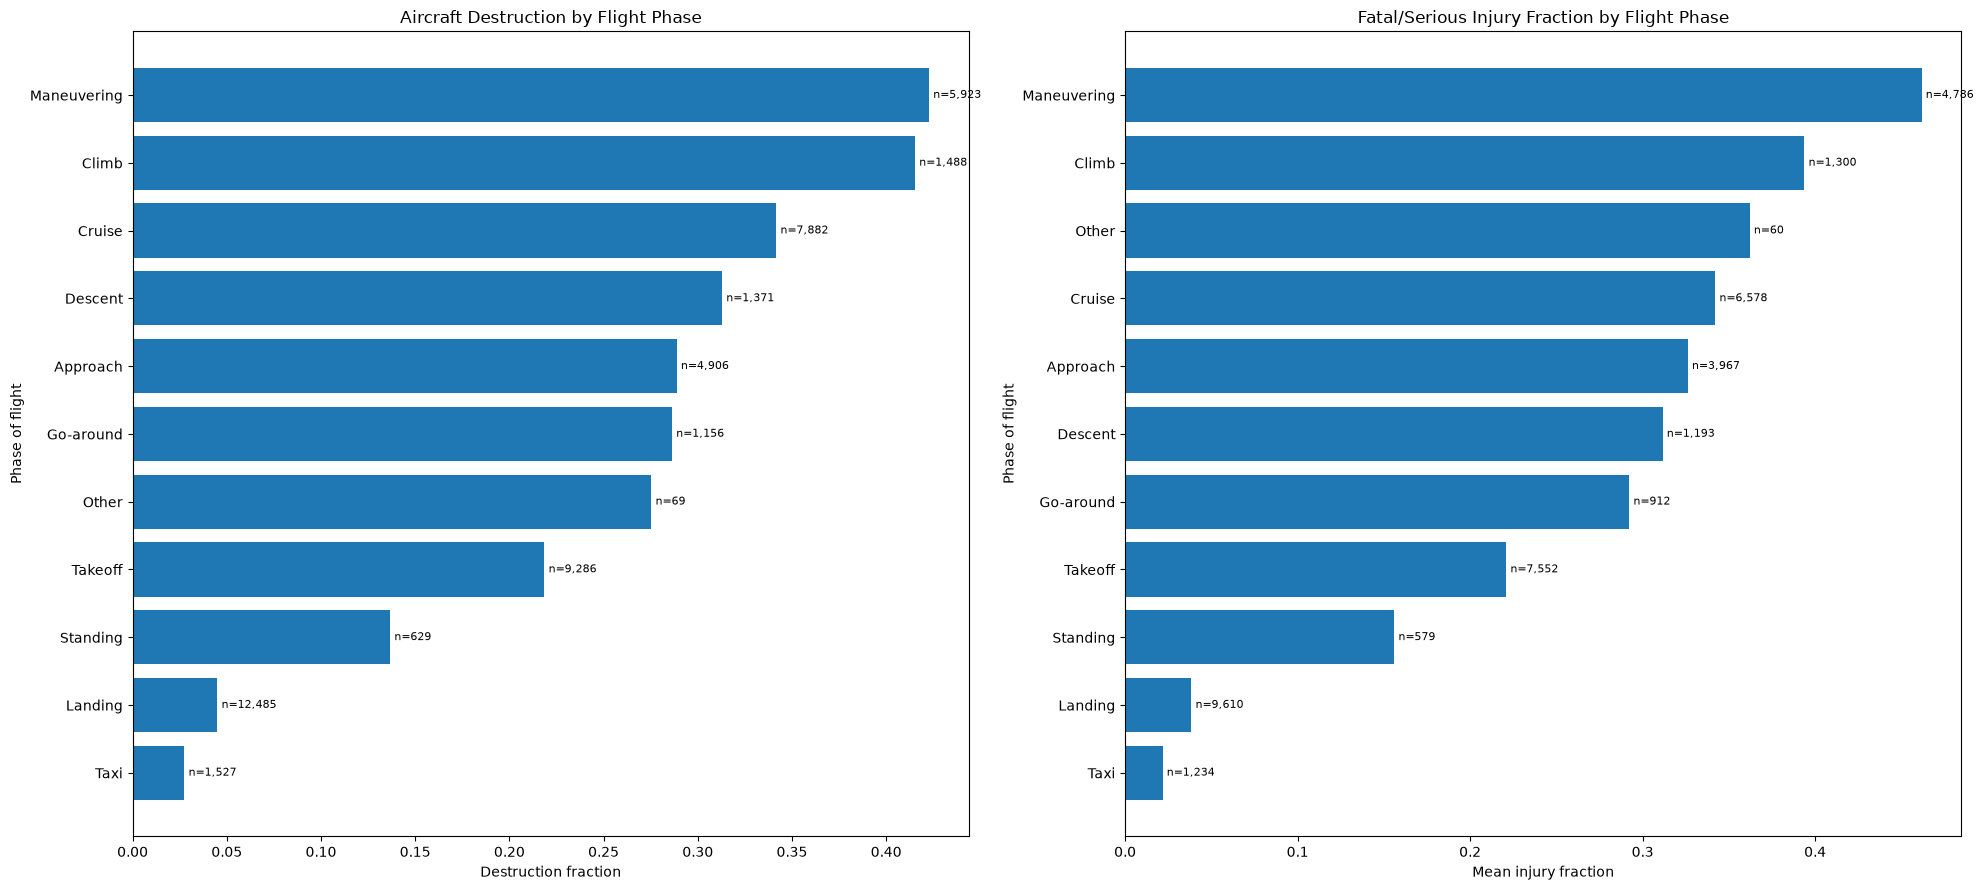

In [55]:

fig, axes = plt.subplots(1, 2, figsize=(20, 9))

# Sort each outcome separately so the bars are easy to compare
destruction_plot = phase_summary.sort_values('Destroyed_Fraction')
injury_plot = phase_summary.sort_values('Mean_Injury_Fraction')

# Aircraft destruction fraction
bars = axes[0].barh(
    destruction_plot['Broad.phase.of.flight'],
    destruction_plot['Destroyed_Fraction']
)
axes[0].bar_label(
    bars,
    labels=[
        f'n={int(n):,}'
        for v, n in zip(
            destruction_plot['Destroyed_Fraction'],
            destruction_plot['Destruction_Count']
        )
    ],
    padding=3,
    fontsize=8
)
axes[0].set_title('Aircraft Destruction by Flight Phase')
axes[0].set_xlabel('Destruction fraction')
axes[0].set_ylabel('Phase of flight')


# Fatal/serious injury fraction
bars = axes[1].barh(
    injury_plot['Broad.phase.of.flight'],
    injury_plot['Mean_Injury_Fraction']
)
axes[1].bar_label(
    bars,
    labels=[
        f'n={int(n):,}'
        for v, n in zip(
            injury_plot['Mean_Injury_Fraction'],
            injury_plot['Injury_Record_Count']
        )
    ],
    padding=3,
    fontsize=8
)
axes[1].set_title('Fatal/Serious Injury Fraction by Flight Phase')
axes[1].set_xlabel('Mean injury fraction')
axes[1].set_ylabel('Phase of flight')

plt.tight_layout()
plt.show()


FINDINGS BASED ON THE FLIGHT PHASE:
Maneuvering is the phase of flight that records the highest destruction fraction and fatal injury
fraction out of other phases. Climb is the second highest in both fractions with fewer recorded 
accidents suggesting fewer accidents occur in this phase but when they do,they can be catastrophic.
Landing is a phase where accidents occur oftenly but the level of damage and loss isn't quite as high 
as other phases. Only Taxi is safer with fewer recorded accidents
